In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython import display
from tqdm import tqdm
import numpy as np

Mearge two files

In [13]:
DATA1 = Path('../data/processed')
DATA2 = Path('../data/external')
CACHE = DATA / 'cache'
domains_df = pd.read_parquet(DATA1 / 'all_publications_enriched.parquet')
researchers_df = pd.read_parquet(DATA2 / 'papers_cleaned.gencat.parquet')
# Merge on DOI
merged_df = researchers_df.merge(
    domains_df[["doi", "domain_name", "year"]],
    on="doi",
    how="left"
)

# Keep columns in the desired order
merged_df = merged_df[[
    "year",
    "doi",
    "orcidResearchers",
    "domain_name"
]]

# Save as parquet
output_file = "merged_data.parquet"
merged_df.to_parquet(output_file, index=False)

print(f"Saved {len(merged_df):,} rows to {output_file}")
print(merged_df.head())

Saved 21,036,994 rows to merged_data.parquet
   year                                 doi       orcidResearchers  \
0  1949                10.1210/jcem-9-9-883  [0000-0002-6245-7933]   
1  1952            10.1002/cber.19520850704  [0000-0001-6112-5913]   
2  1952  10.1111/j.1365-2133.1952.tb15900.x  [0000-0002-6245-7933]   
3  1953                 10.1038/jid.1953.55  [0000-0002-6245-7933]   
4  1954       10.1016/s0022-5347(17)67795-4  [0000-0002-6245-7933]   

         domain_name  
0    Health Sciences  
1  Physical Sciences  
2    Health Sciences  
3      Life Sciences  
4    Health Sciences  


In [41]:
cleaned_papers = pd.read_parquet(DATA1 / 'publications_research_year_domain.parquet')
cleaned_papers = cleaned_papers.drop_duplicates(subset="doi")

In [42]:
domains = []
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Health Sciences']) 
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Physical Sciences'])
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Life Sciences']) 
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Social Sciences']) 

exploded_domains = []
for i in range(0,4):
    exploded_domains.append(domains[i].explode('orcidResearchers'))
grouped = []
difs = []
difs_norm = []
for i in range(0,4):
    grouped.append(exploded_domains[i]['orcidResearchers'].value_counts())
    vc = grouped[i].value_counts().sort_index()            # counts per value, ascending x

    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })
    dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
    # optional: "fraction >= x" instead of "> x"
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()
    
    x = dif["value"].to_numpy(dtype=float)
    y = dif["surv_ge"].to_numpy(dtype=float)
    # Area under the curve
    area = np.trapezoid(x, y)

    # Normalize so area = 1
    if area < 0:
        x_norm = x / (-area)
    else:
        x_norm = x
    difs.append([dif['value'],dif["surv_ge"]])
    difs_norm.append([x_norm,y])
print('ja està!')

ja està!


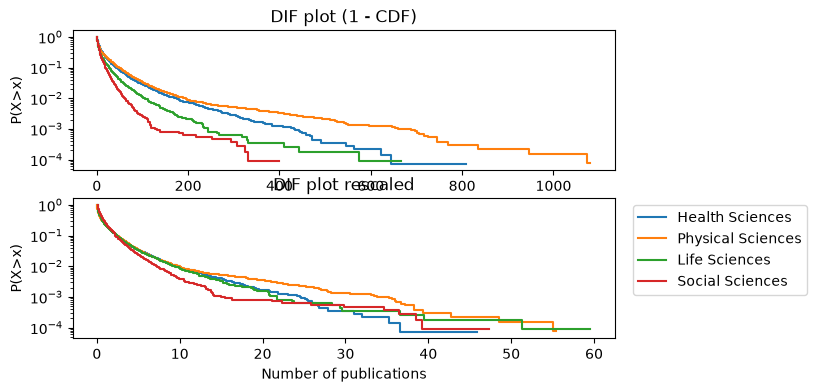

In [45]:
fig, ax = plt.subplots(nrows=2,ncols=1,figsize=(7, 4))
fields_labels = ['Health Sciences','Physical Sciences','Life Sciences','Social Sciences']
for i in range(0,4):
    ax[0].step(difs[i][0], difs[i][1],label = fields_labels[i])
ax[0].set_xlabel("Number of publications")
ax[0].set_ylabel("P(X>x)")
ax[0].set_title("DIF plot (1 - CDF)")
#ax[0].set_xscale("log")
ax[0].set_yscale("log")

for i in range(0,4):
    ax[1].step(difs_norm[i][0], difs_norm[i][1],label = fields_labels[i])
ax[1].set_xlabel("Number of publications")
ax[1].set_ylabel("P(X>x)")
ax[1].set_title("DIF plot rescaled")
#ax[1].set_xscale("log")
ax[1].set_yscale("log")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()